# Ray Data: from pandas and back

Turns a pandas DataFrame into a Ray Dataset, adds a column row by row with map, and collects the result as a DataFrame again.

**When to use it.** Scaling an existing pandas step without rewriting the code around it.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

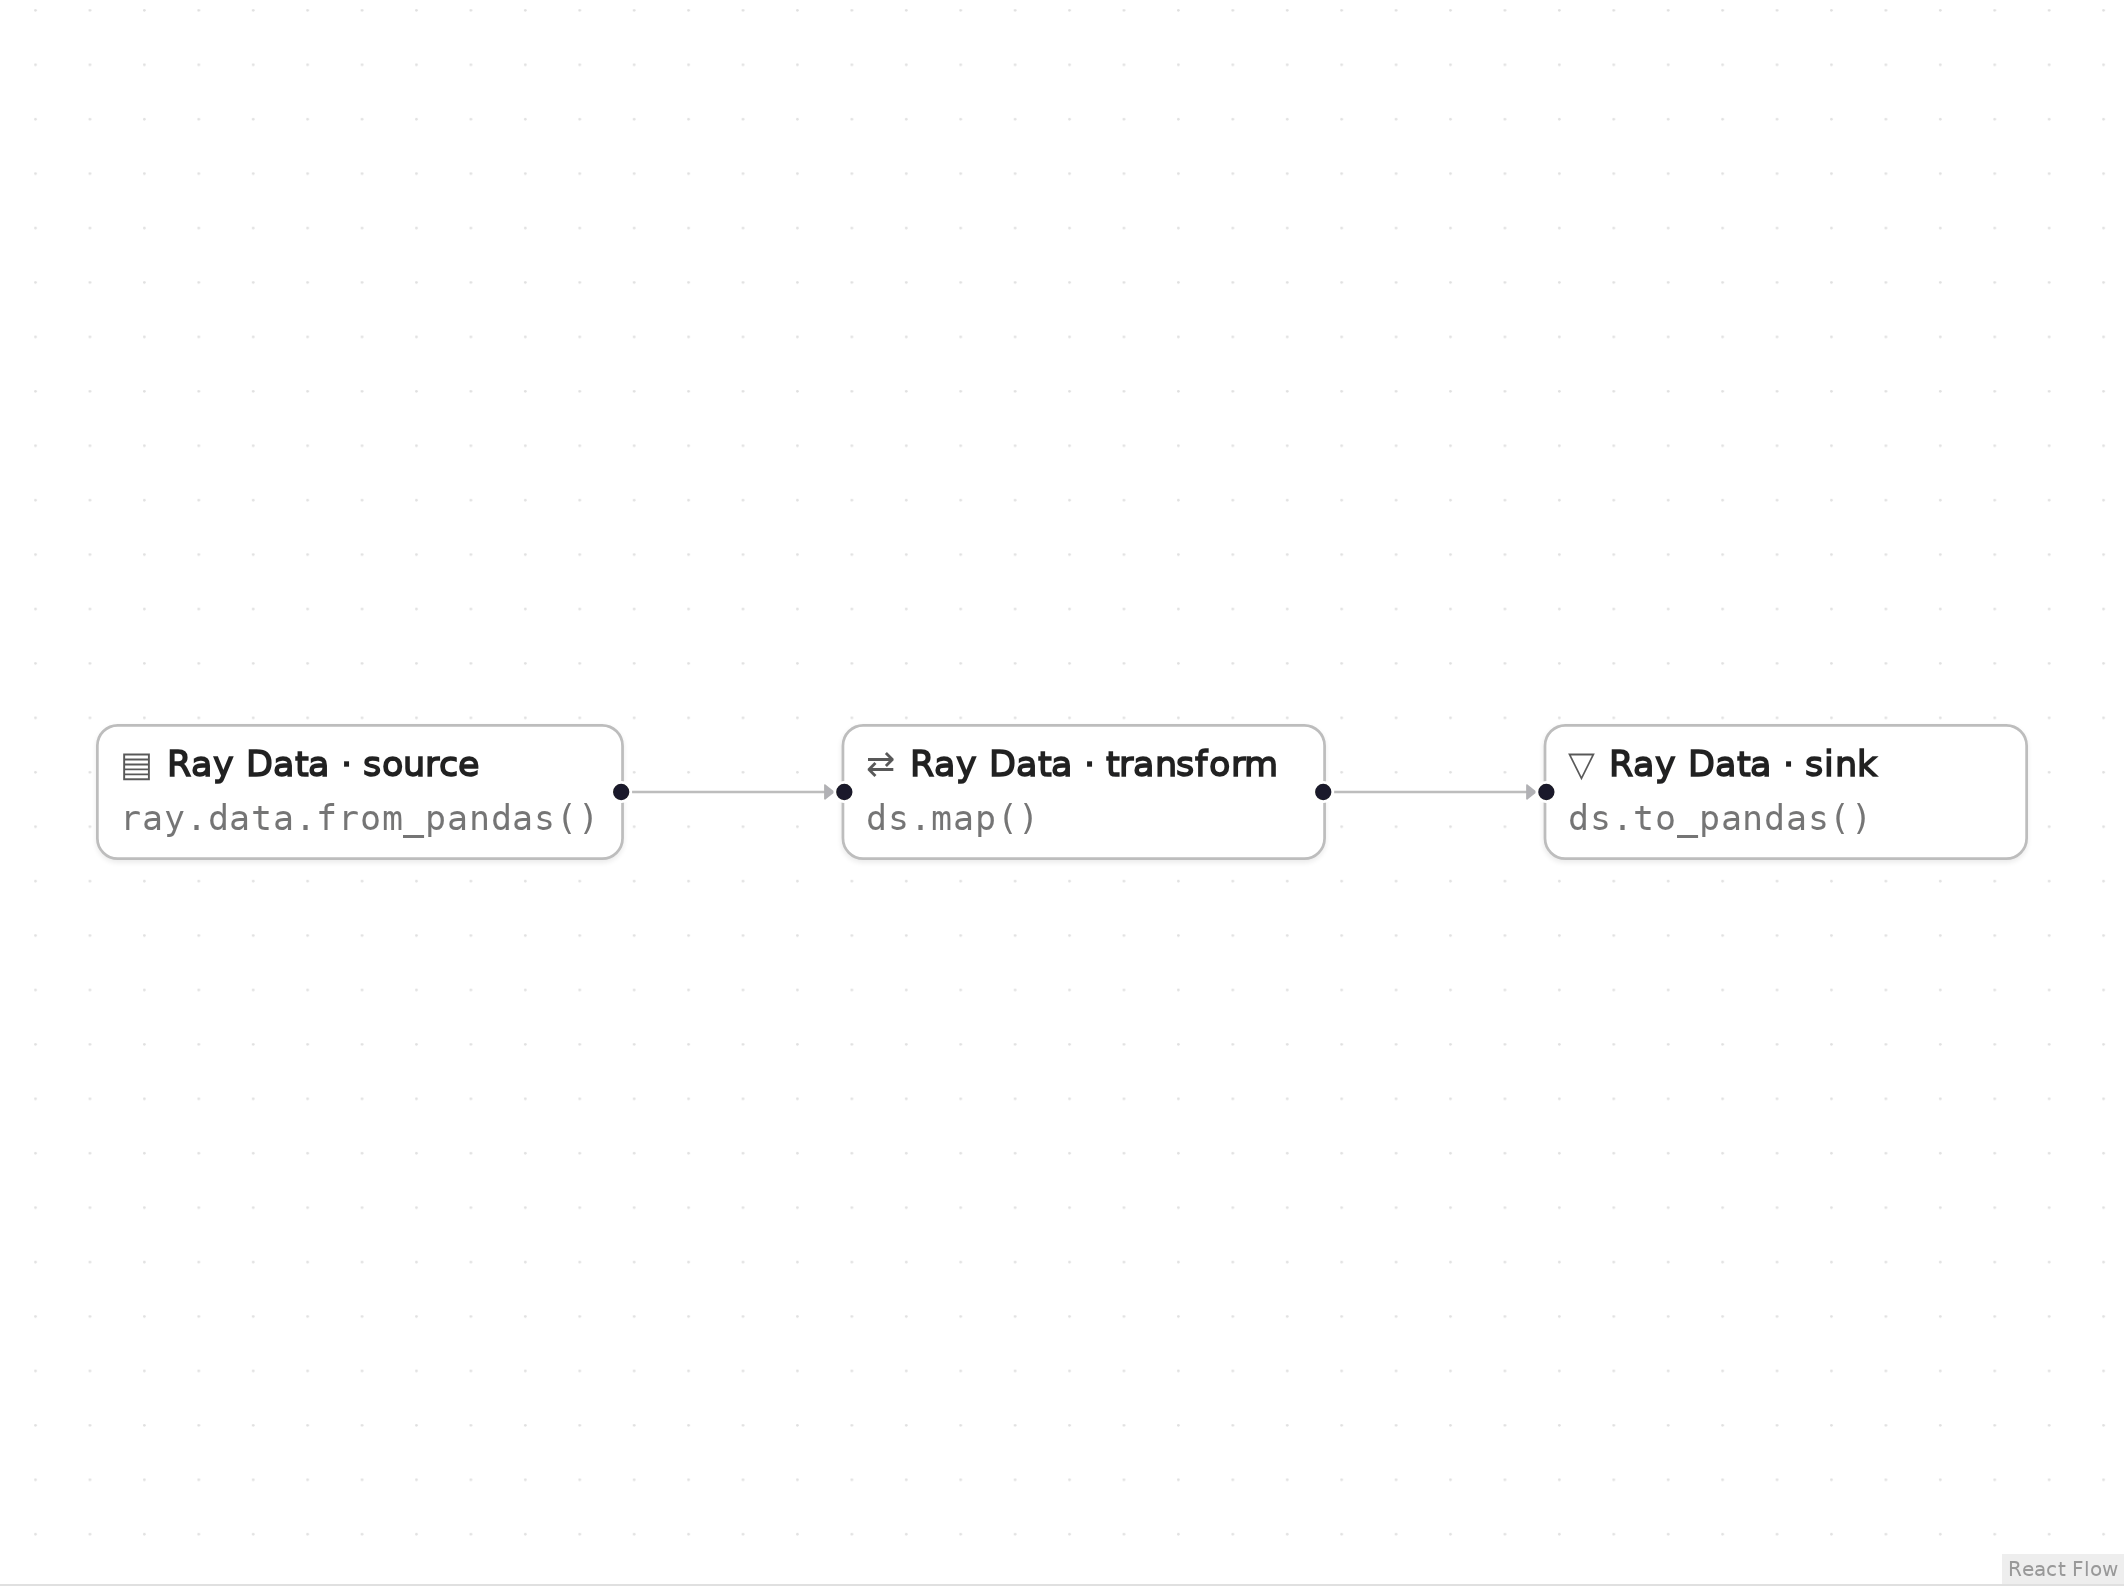

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import pandas as pd

df = pd.DataFrame({"item": ["apple", "pear", "fig"], "price": [1.5, 2.0, 3.25], "qty": [4, 2, 8]})


def add_total(row):
    row["total"] = row["price"] * row["qty"]
    return row

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ds = ray.data.from_pandas(df)
ds = ds.map(add_total)
out_df = ds.to_pandas()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
out = out_df.sort_values("item").reset_index(drop=True)
assert list(out["item"]) == ["apple", "fig", "pear"], out
assert list(out["total"]) == [6.0, 26.0, 4.0], out
print(out)

    item  price  qty  total
0  apple   1.50    4    6.0
1    fig   3.25    8   26.0
2   pear   2.00    2    4.0


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 8)

```python
ds = ray.data.from_pandas(df)
```

from_pandas(df) wraps the notebook DataFrame df as a Dataset.

**Transform** (node `n2`, line 9)

```python
ds = ds.map(add_total)
```

map(add_total) calls the function once per row (a dict).

**Sink** (node `n3`, line 10)

```python
out_df = ds.to_pandas()
```

to_pandas() gathers the rows back into one DataFrame on the driver.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()